# GAN (Generative Adversarial Networks)

En este practico vamos a estar implementando el modelo generativo [GAN (Generative Adversarial Networks)](https://arxiv.org/pdf/1406.2661)

In [2]:
import math
import torch
import numpy as np
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torchvision.utils as vutils
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from mpl_toolkits.axes_grid1 import ImageGrid

In [3]:
# Transformamos los datos a tensores y los normalizamos
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
    ])

# Descargamos el dataset
dataset = datasets.FashionMNIST(root='./data', download=True, transform=transform)

# Creamos el dataloader
batch_size = 64
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Running on {device}")

Running on cuda


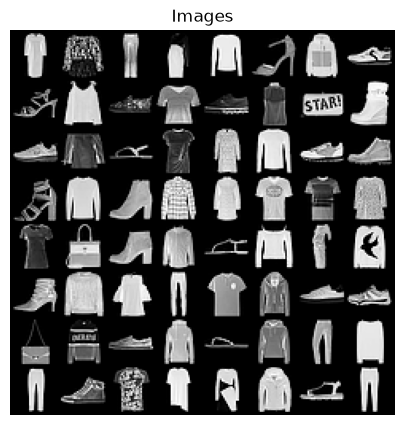

In [4]:
def show_imgs(imgs, title="Images"):
    plt.figure(figsize=(5,5))
    plt.axis("off")
    plt.title(title)
    plt.imshow(np.transpose(vutils.make_grid(imgs, padding=2, normalize=True).cpu(),(1,2,0)))
    plt.show()

real_batch = next(iter(dataloader))[0][:64]
img_shape = real_batch[0].shape
show_imgs(real_batch)

## Definimos el modelo
Las GANs (Generative Adversarial Networks) consisten en dos redes que compiten entre sí: un generador que crea datos falsos y un discriminador que trata de distinguirlos de los datos reales, mejorando así la calidad de los datos generados con el tiempo.

### Generador
Es una red neuronal que, partiendo de un espacio latente, crea datos sintéticos con el objetivo de parecerse a los datos reales.

Esta "parte" del modelo es la que nos va a servir luego para la generación.

In [5]:
class Generator(nn.Module):
    def __init__(self, latent_dim, number_feature_maps, output_channels):
        super(Generator, self).__init__()
        self.latent_feature_maps = latent_dim
        self.main = nn.Sequential(
            # Tamaño entrada (bs, tamaño latente, 1, 1)
            nn.ConvTranspose2d(latent_dim, number_feature_maps * 4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*4, 7 , 7)
            nn.ConvTranspose2d(number_feature_maps * 4, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*2, 14 , 14)
            nn.ConvTranspose2d(number_feature_maps * 2, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps, 28 , 28)
            nn.ConvTranspose2d(number_feature_maps, output_channels, 3, 1, 1, bias=False),
            nn.Tanh(),
            # Tamaño salida (bs, 1, 28 , 28)
        )

    def forward(self, input):
        result = self.main(input)
        return result

### Discriminador

Es una red neuronal que clasifica los datos como reales o generados. Su tarea es distinguir entre los datos reales y los falsos producidos por el generador, ayudando así a mejorar la calidad de ambos.

In [6]:
class Discriminator(nn.Module):
    def __init__(self, input_channels, number_feature_maps, output_dim):
        super(Discriminator, self).__init__()
        self.conv_layers = nn.Sequential(
            # Tamaño entrada (bs, 1, 28, 28)
            nn.Conv2d(input_channels, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps, 14, 14)
            nn.Conv2d(number_feature_maps, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*2, 7, 7)
            nn.Conv2d(number_feature_maps * 2, number_feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*4, 4, 4)
        )

        self.fully_connected = nn.Sequential(
            nn.Flatten(1),
            # Tamaño (bs, 3*3*number_feature_maps*4)
            nn.Linear(3*3*number_feature_maps*4, output_dim),
            nn.Sigmoid()
        )

    def forward(self, input):
        res = self.conv_layers(input)
        res = self.fully_connected(res)
        return res

## Definición de hyperparámetros y creación del modelo.

In [7]:
# Definimos hyperparámetros
latent_dim = 100
discriminator_lr = 0.0002
generator_lr = 0.002
n_epochs = 12
number_feature_maps = 64
channels = img_shape[0]  # 1 canal para Fashion MNIST


# Inicialización de pesos que proponen en el paper de DCGAN (normal con media 0 y desvío 0.02).
# Sin esto (y sin cambiar los betas de Adam) el discriminador se volvía perfecto en pocas
# iteraciones y el generador no aprendía nada.
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


# Creamos el generador y el discriminador
generator = Generator(latent_dim, number_feature_maps, channels).to(device)
discriminator = Discriminator(channels, number_feature_maps, 1).to(device)
generator.apply(weights_init)
discriminator.apply(weights_init)

# Definir la función de pérdida
adversarial_loss = nn.BCELoss()

In [8]:
# Definimos la función de entrenamiento del modelo
def train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device, verbose=False):
    # Creamos los dos optimizadores. 
    # Recordar que estos optimizadores son distintos ya que cada uno precisa los parametros
    #    a entrenar y el discriminador y el generador se entrenan por separado.
    # Usamos betas=(0.5, 0.999) como en el paper de DCGAN. Con los valores por defecto (0.9, 0.999)
    #    el entrenamiento colapsaba (loss del discriminador ~0 y el generador solo producía ruido).
    optimizer_G = optim.Adam(generator.parameters(), lr=generator_lr, betas=(0.5, 0.999))
    optimizer_D = optim.Adam(discriminator.parameters(), lr=discriminator_lr, betas=(0.5, 0.999))

    # Guardamos las pérdidas para poder graficarlas después
    g_losses, d_losses = [], []

    for epoch in tqdm(range(n_epochs)):
        for i, (imgs, _) in enumerate(dataloader):
            bs = imgs.size(0)

            # Creamos las etiquetas para el discriminador
            valid = torch.ones(bs, 1, device=device)
            fake = torch.zeros(bs, 1, device=device)

            real_imgs = imgs.to(device)

            # Creamos ruido dentro del espacio latente usando una normal
            latent_shape = (bs, latent_dim, 1, 1)
            z = torch.randn(latent_shape)
            z = z.to(device)

            
            # Entrenar el generador
            # El generador busca que el discriminador clasifique sus imágenes como reales (valid)
            optimizer_G.zero_grad()
            gen_imgs = generator(z)
            g_loss = adversarial_loss(discriminator(gen_imgs), valid)
            g_loss.backward()
            optimizer_G.step()

            # Entrenar el discrminador (recordar hacer el detach de las imagenes generadas)
            # Las reales tienen que dar 1 y las generadas 0
            optimizer_D.zero_grad()
            real_loss = adversarial_loss(discriminator(real_imgs), valid)
            fake_loss = adversarial_loss(discriminator(gen_imgs.detach()), fake)
            d_loss = (real_loss + fake_loss) / 2
            d_loss.backward()
            optimizer_D.step()

            g_losses.append(g_loss.item())
            d_losses.append(d_loss.item())

            if verbose: print(f"[Epoch {epoch}/{n_epochs}] [Batch {i}/{len(dataloader)}] [D loss: {d_loss.item()}] [G loss: {g_loss.item()}]")

        if epoch % 4 == 0:
                show_imgs(gen_imgs.data[:32], title=f"Epoch {epoch}")

    return g_losses, d_losses


def plot_losses(g_losses, d_losses):
    plt.figure(figsize=(10, 4))
    plt.plot(g_losses, label="Generador", alpha=0.7)
    plt.plot(d_losses, label="Discriminador", alpha=0.7)
    plt.xlabel("Iteración")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

## Entrenamiento del modelo

  0%|          | 0/12 [00:00<?, ?it/s]

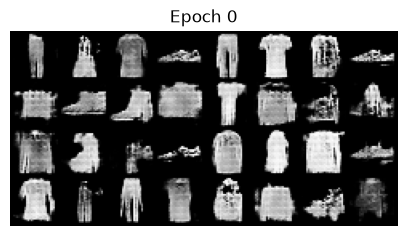

 33%|███▎      | 4/12 [01:13<02:26, 18.31s/it]

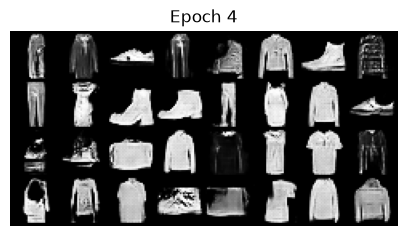

 67%|██████▋   | 8/12 [02:27<01:13, 18.42s/it]Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].


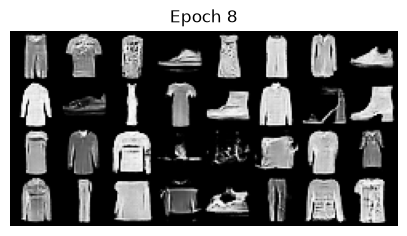

100%|██████████| 12/12 [03:40<00:00, 18.40s/it]


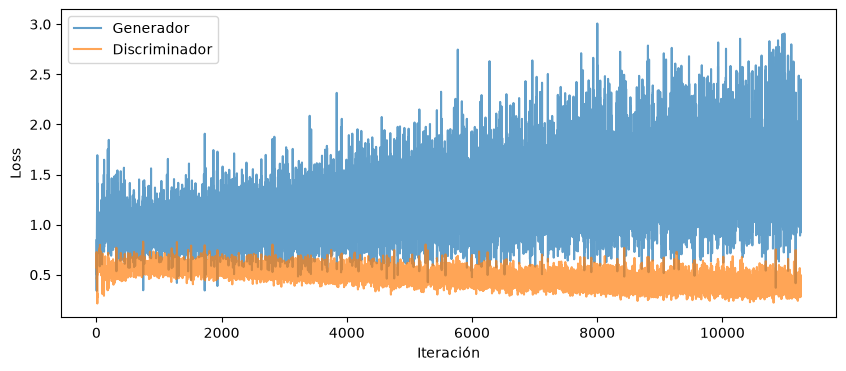

In [9]:
# Comenzamos el entrenamiento del modelo!
g_losses, d_losses = train(generator, discriminator, adversarial_loss, dataloader, n_epochs, device)
plot_losses(g_losses, d_losses)

## Generación de datos

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].


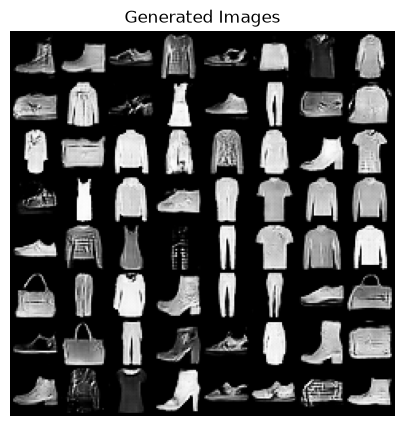

In [10]:
def generate(generator, num_imgs=32):
    # Creamos un tensor de ruido dentro del espacio latente
    z = torch.randn(num_imgs, latent_dim, 1, 1, device=device)
    # Hacemos el forward pass del generador (sin calcular gradientes)
    with torch.no_grad():
        gen_imgs = generator(z)
    return gen_imgs

imgs = generate(generator, num_imgs=64)
show_imgs(imgs, title="Generated Images")

## Ejercicios:

1. Complete el codigo faltante y entrene una GAN que genere imágenes de Fashion MNIST.
2. Responda las siguientes preguntas:
    - ¿En qué afecta el tamaño del espacio latente?
    - ¿Por qué entrenamos al discriminador y al generador alternativamente?
    - ¿Qué tamaño tiene la salida del discriminador y por qué? ¿Y el generador?
    - ¿Qué tipo de activación final se usa en el discriminador y por qué?
    - ¿Cuál es el propósito de la competencia entre el generador y el discriminador en las GANs? Explica cómo esto contribuye a la mejora del modelo.
    - Entrene una GAN que genere imágenes del dataset [SVHN (street view house number)](http://ufldl.stanford.edu/housenumbers/).
    - Comente los resultados obtenidos con este dataset.

## Respuestas

**¿En qué afecta el tamaño del espacio latente?**

El espacio latente es de donde sale el vector de ruido $z$ que recibe el generador, así que su tamaño determina cuánta "información" tiene el generador para decidir qué imagen producir. Si es muy chico, el generador tiene pocas dimensiones para representar toda la variedad del dataset (distintas prendas, formas, texturas) y tiende a generar imágenes muy parecidas entre sí, lo que favorece el *mode collapse*. Si es demasiado grande, muchas dimensiones terminan siendo redundantes, aumenta la cantidad de parámetros de la primera capa y el entrenamiento se hace un poco más lento sin que la calidad mejore necesariamente. El tamaño de las imágenes generadas no cambia, ya que solo afecta a la primera capa del generador. Usamos 100, que es el valor que se usa en el paper de DCGAN y es más que suficiente para un dataset como Fashion MNIST.

**¿Por qué entrenamos al discriminador y al generador alternativamente?**

Porque sus objetivos son opuestos: el discriminador quiere clasificar bien las imágenes y el generador quiere que se equivoque. Si se actualizaran los dos con una misma pérdida, lo que mejora a uno empeora al otro. Por eso en cada iteración se deja uno fijo y se actualiza el otro: cuando entrenamos el generador, el discriminador solo se usa para calcular la pérdida (solo se hace el `step` de `optimizer_G`), y cuando entrenamos el discriminador se hace `detach` de las imágenes generadas para que el gradiente no llegue al generador. Además, alternar ayuda a que ninguno de los dos se adelante demasiado: si el discriminador se vuelve muy bueno, el gradiente que recibe el generador es casi nulo y deja de aprender; y si es muy malo, el generador no recibe una señal útil.

**¿Qué tamaño tiene la salida del discriminador y por qué? ¿Y el generador?**

El discriminador devuelve un tensor de tamaño `(bs, 1)`, es decir, un único número por imagen. Esto es porque es un clasificador binario: ese valor es la probabilidad de que la imagen sea real. El generador devuelve `(bs, 1, 28, 28)` para Fashion MNIST (y `(bs, 3, 32, 32)` en SVHN), o sea, exactamente el mismo tamaño que las imágenes reales. Tiene que ser así porque las imágenes generadas entran al mismo discriminador que las reales y la idea es que no se puedan distinguir.

**¿Qué tipo de activación final se usa en el discriminador y por qué?**

Una sigmoide, que lleva la salida al rango $(0, 1)$ y permite interpretarla como la probabilidad de que la imagen sea real. Además es lo que necesita la `BCELoss`, que espera probabilidades y no valores arbitrarios. Otra opción sería sacar la sigmoide y usar `BCEWithLogitsLoss`, que la incluye internamente y es más estable numéricamente. Como comparación, el generador termina en `Tanh` porque las imágenes están normalizadas en $[-1, 1]$.

**¿Cuál es el propósito de la competencia entre el generador y el discriminador en las GANs? Explica cómo esto contribuye a la mejora del modelo.**

La competencia es lo que reemplaza a una función de pérdida "a mano". No hay una forma sencilla de medir si una imagen generada parece real, entonces se entrena una red (el discriminador) que aprende a detectar las diferencias entre las imágenes reales y las generadas. El generador usa los gradientes del discriminador como señal de qué tiene que cambiar para parecerse más a los datos reales. A medida que el discriminador mejora, encuentra diferencias más sutiles, y eso obliga al generador a mejorar también; es un juego minimax en el que cada uno empuja al otro. En el óptimo teórico el generador reproduce la distribución de los datos y el discriminador no puede hacer nada mejor que responder 0.5 para todo. En la práctica no se llega a ese equilibrio y las pérdidas oscilan en vez de bajar, como se ve en la gráfica de arriba, por lo que la pérdida no sirve mucho para medir la calidad y hay que mirar las imágenes generadas.

Estas imágenes son de (3, 32, 32). Debe crear un nuevo generador y dicriminador para ajustarse a estas nuevas dimensiones.

In [11]:
import io
import os
import urllib.request
from PIL import Image

transform = transforms.Compose([
    transforms.ToTensor(),
    # Normalizamos a [-1, 1] igual que con Fashion MNIST, porque el generador termina en Tanh.
    # Con Normalize(0, 1) las imágenes quedan en [0, 1] y el generador nunca usaría la parte negativa.
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])


# El servidor de Stanford de donde descarga torchvision a veces no responde,
# así que si falla bajamos la misma partición (train, cropped digits) desde el mirror de Hugging Face.
class SVHNParquet(torch.utils.data.Dataset):
    URL = "https://huggingface.co/datasets/ufldl-stanford/svhn/resolve/main/cropped_digits/train-00000-of-00001.parquet"

    def __init__(self, root, transform=None):
        import pandas as pd
        path = os.path.join(root, "svhn_train.parquet")
        if not os.path.exists(path):
            print("Descargando SVHN desde Hugging Face...")
            os.makedirs(root, exist_ok=True)
            urllib.request.urlretrieve(self.URL, path)
        df = pd.read_parquet(path)
        # Decodificamos todas las imágenes una sola vez (quedan en un array de (N, 32, 32, 3))
        self.data = np.stack([np.array(Image.open(io.BytesIO(img["bytes"])).convert("RGB")) for img in df["image"]])
        self.labels = df["label"].values
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        img = self.data[i]
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.labels[i])


try:
    dataset = datasets.SVHN(root='./data', download=True, transform=transform)
except Exception as e:
    print(f"No se pudo descargar con torchvision ({e})")
    dataset = SVHNParquet(root='./data', transform=transform)

print(f"Cantidad de imágenes: {len(dataset)}")
print(f"Image size: {dataset[0][0].shape}")

batch_size = 64
dataloader = DataLoader(dataset=dataset, batch_size=batch_size, shuffle=True)
real_batch = next(iter(dataloader))[0]
img_shape = real_batch[0].shape
show_imgs(real_batch, "SVHN Images")

No se pudo descargar con torchvision (<urlopen error [WinError 10060] A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond>)


ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip, conda, or your preferred package management tool to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip, conda, or your preferred package management tool to install the fastparquet package.

### Generador y discriminador para SVHN

La idea es la misma que antes, pero ahora la entrada/salida es de (3, 32, 32). Como 32 es potencia de 2 se puede ir de 4 → 8 → 16 → 32 duplicando en cada capa, que queda más prolijo que con 28.

In [ ]:
class GeneratorSVHN(nn.Module):
    def __init__(self, latent_dim, number_feature_maps, output_channels):
        super(GeneratorSVHN, self).__init__()
        self.main = nn.Sequential(
            # Tamaño entrada (bs, tamaño latente, 1, 1)
            nn.ConvTranspose2d(latent_dim, number_feature_maps * 4, 4, 1, 0, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*4, 4, 4)
            nn.ConvTranspose2d(number_feature_maps * 4, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps*2, 8, 8)
            nn.ConvTranspose2d(number_feature_maps * 2, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.ReLU(True),
            # Tamaño (bs, number_feature_maps, 16, 16)
            nn.ConvTranspose2d(number_feature_maps, output_channels, 4, 2, 1, bias=False),
            nn.Tanh(),
            # Tamaño salida (bs, 3, 32, 32)
        )

    def forward(self, input):
        return self.main(input)


class DiscriminatorSVHN(nn.Module):
    def __init__(self, input_channels, number_feature_maps, output_dim):
        super(DiscriminatorSVHN, self).__init__()
        self.conv_layers = nn.Sequential(
            # Tamaño entrada (bs, 3, 32, 32)
            nn.Conv2d(input_channels, number_feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps, 16, 16)
            nn.Conv2d(number_feature_maps, number_feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*2, 8, 8)
            nn.Conv2d(number_feature_maps * 2, number_feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(number_feature_maps * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # Tamaño (bs, number_feature_maps*4, 4, 4)
        )

        self.fully_connected = nn.Sequential(
            nn.Flatten(1),
            # Tamaño (bs, 4*4*number_feature_maps*4)
            nn.Linear(4*4*number_feature_maps*4, output_dim),
            nn.Sigmoid()
        )

    def forward(self, input):
        res = self.conv_layers(input)
        return self.fully_connected(res)

In [ ]:
# Mismos hiperparámetros que para Fashion MNIST
channels = img_shape[0]  # 3 canales (RGB)
n_epochs = 12

generator_svhn = GeneratorSVHN(latent_dim, number_feature_maps, channels).to(device)
discriminator_svhn = DiscriminatorSVHN(channels, number_feature_maps, 1).to(device)
generator_svhn.apply(weights_init)
discriminator_svhn.apply(weights_init)

# Chequeo rápido de dimensiones
with torch.no_grad():
    z_test = torch.randn(2, latent_dim, 1, 1, device=device)
    print("Salida generador:", generator_svhn(z_test).shape)
    print("Salida discriminador:", discriminator_svhn(generator_svhn(z_test)).shape)

In [ ]:
g_losses_svhn, d_losses_svhn = train(generator_svhn, discriminator_svhn, adversarial_loss, dataloader, n_epochs, device)
plot_losses(g_losses_svhn, d_losses_svhn)

In [ ]:
imgs = generate(generator_svhn, num_imgs=64)
show_imgs(imgs, title="Generated Images (SVHN)")

### Comentarios sobre los resultados con SVHN

Para este dataset se usaron la misma arquitectura y los mismos hiperparámetros que con Fashion MNIST, adaptando solamente las capas a imágenes de (3, 32, 32). También se cambió la normalización de la celda de carga a $[-1, 1]$ para que coincida con la `Tanh` del generador, porque con `Normalize(0, 1)` las imágenes reales quedaban en $[0, 1]$ y el discriminador podía distinguirlas de las falsas solo por el rango de valores.

El generador aprende a producir imágenes que se parecen a números de casas: se ven dígitos centrados (algunos con partes de otros dígitos a los costados, igual que en el dataset real) y fondos con colores variados. De todas formas la calidad es más baja que en Fashion MNIST: muchas imágenes son borrosas, varios dígitos no se pueden leer bien y aparecen algunos artefactos en forma de cuadrícula, típicos de las convoluciones transpuestas.

Esto tiene sentido, porque SVHN es bastante más difícil que Fashion MNIST. Las imágenes son a color y tienen el triple de valores por imagen. Además vienen de fotos reales, con fondos, iluminación, tipografías y colores muy distintos entre sí, y muchas veces aparecen dígitos vecinos cortados. En Fashion MNIST, en cambio, el fondo es siempre negro y las prendas están centradas. Con más épocas, o con un generador y un discriminador con más filtros, seguramente los resultados mejorarían.

Las pérdidas se comportan parecido a Fashion MNIST: oscilan en lugar de bajar de forma sostenida y ninguna de las dos llega a cero, lo que indica que ninguna de las dos redes domina a la otra.